# Decentralized & Constrained Bayesian Linear Regression

Synthetic data (Section 5.2 of the paper):
$y_j=\beta_*^\top X_j+\epsilon_j$, $\epsilon_j\sim\mathcal N(0,\sigma^2)$, $X_j\sim\mathcal N(0,I_2)$, $\beta_*=[1,1]^\top$.
The prior is uniform on the $\ell_2$-ball $\mathcal K=\{\|\beta\|_2\le s\}$, so the posterior is
$\mathcal N\big(\beta_{\rm OLS},\sigma^2(X^\top X)^{-1}\big)$ restricted to $\mathcal K$, and **exact** posterior samples are obtained by rejection.
$\mathcal W_2(\mathrm{Law}(\cdot),\pi)$ is computed by exact optimal transport between $M$ copies of the network and $M$ exact samples.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "experiments" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src import (NETWORK_NAMES, mixing_matrix, de_psgld, psgld, w2_empirical,
                 problems, apply_style, COLORS)

apply_style()
FIG_DIR = ROOT / "figure"
FIG_DIR.mkdir(exist_ok=True)
%matplotlib inline

## Parameters

In [2]:
# problem
n_DATA = 10_000     # total number of observations
N      = 10         # number of agents (n_DATA / N points per agent)
SIG2   = 0.25       # noise variance
S      = 1.4        # radius of the l2-ball (||beta*|| = 1.414)
BATCH  = 20         # mini-batch size per agent
DATA_SEED = 11

# sampler
GAMMA    = 1e-7     # small gamma: the posterior is very concentrated (sd ~ 0.005)
ETA_FRAC = 0.6
N_ITER   = 12_000
RECORD_EVERY = 300  # each record solves 4 assignment problems of size M (slowest part)
M        = 1000
SEED     = 1
NETWORKS = ["full", "ring", "star"]
AGENTS_TO_SHOW = [0, 4, 8]

ZOOM = 0.022        # half-width of the contour-plot window around the boundary point
SAVE_FIGS = True

## Problem and stepsize

In [3]:
prob = problems.linear_regression(n=n_DATA, N=N, sig2=SIG2, batch=BATCH, s=S, seed=DATA_SEED)
eta = ETA_FRAC * prob.eta_max(GAMMA)
eta_c = eta / N
ref = prob.exact_samples(M, seed=5)
mc_floor = w2_empirical(prob.exact_samples(M, seed=6), ref)
print(f"||beta_OLS|| = {np.linalg.norm(prob.beta_ols):.4f},  s = {S},  posterior sd = {np.sqrt(np.linalg.eigvalsh(prob.post_cov))}")
print(f"L = {prob.L:.1f},  mu = {prob.mu:.1f},  eta = {eta:.3e},  eta_central = {eta_c:.3e}")
print(f"Monte Carlo floor of the W2 estimator: {mc_floor:.4f}")

||beta_OLS|| = 1.4174,  s = 1.4,  posterior sd = [0.00495826 0.00506368]
L = 4404.1,  mu = 3516.7,  eta = 1.996e-07,  eta_central = 1.996e-08
Monte Carlo floor of the W2 estimator: 0.0005


## Run

In [4]:
x0 = 0.05 * np.random.default_rng(3).standard_normal((M, N, prob.d))   # near the origin
def record(B, k):
    return [w2_empirical(B[:, i], ref) for i in AGENTS_TO_SHOW], w2_empirical(B.mean(1), ref)

res = {}
for kind in NETWORKS:
    W, rho, _ = mixing_matrix(kind, N)
    BT, out = de_psgld(x0, W, prob.stoch_grad, prob.proj, eta, GAMMA, N_ITER, seed=SEED,
                       record=record, record_every=RECORD_EVERY, progress=NETWORK_NAMES[kind])
    res[kind] = dict(rho=rho, agents=np.array([o[0] for o in out]),
                     mean=np.array([o[1] for o in out]), final=BT)

BC, out_c = psgld(x0[:, 0], prob.stoch_grad_central, prob.proj, eta_c, GAMMA, N_ITER, seed=SEED,
                  record=lambda B, k: w2_empirical(B, ref), record_every=RECORD_EVERY, progress="PSGLD")
w2_central = np.array(out_c)
iters = np.arange(0, N_ITER + 1, RECORD_EVERY)

  Fully Connected: 12000/12000 iterations (113s)
  Circular: 12000/12000 iterations (113s)
  Star: 12000/12000 iterations (114s)
  PSGLD: 12000/12000 iterations (74s)


## $\mathcal W_2$ vs iterations

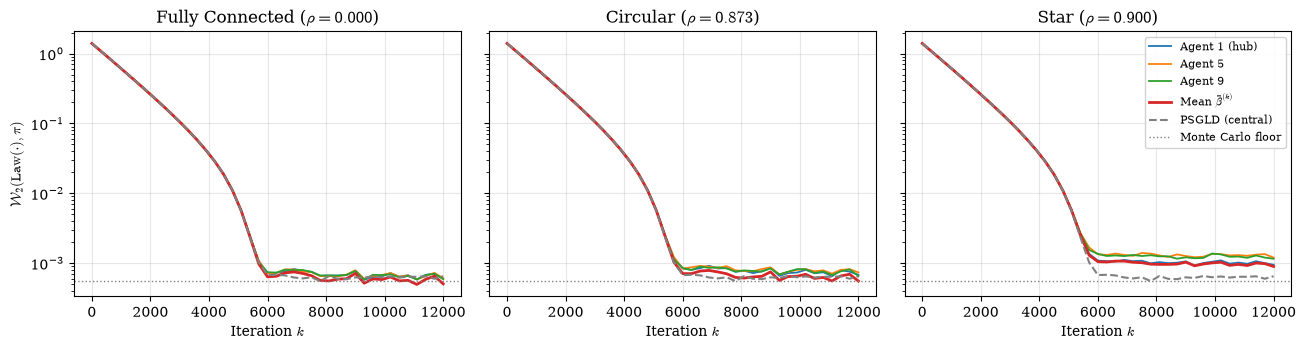

In [5]:
fig, axes = plt.subplots(1, len(NETWORKS), figsize=(4.4 * len(NETWORKS), 3.6), sharey=True, squeeze=False)
for ax, kind in zip(axes[0], NETWORKS):
    r = res[kind]
    for j, i in enumerate(AGENTS_TO_SHOW):
        lab = f"Agent {i+1}" + (" (hub)" if kind == "star" and i == 0 else "")
        ax.plot(iters, r["agents"][:, j], color=COLORS[j], lw=1.3, label=lab)
    ax.plot(iters, r["mean"], color=COLORS[3], lw=2, label=r"Mean $\bar\beta^{(k)}$")
    ax.plot(iters, w2_central, color="gray", ls="--", lw=1.5, label="PSGLD (central)")
    ax.axhline(mc_floor, color="gray", ls=":", lw=1, label="Monte Carlo floor")
    ax.set_yscale("log"); ax.set_xlabel("Iteration $k$")
    ax.set_title(f"{NETWORK_NAMES[kind]} ($\\rho={r['rho']:.3f}$)")
axes[0, 0].set_ylabel(r"$\mathcal{W}_2(\mathrm{Law}(\cdot),\pi)$")
axes[0, -1].legend(fontsize=8)
fig.tight_layout()
if SAVE_FIGS:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"exp2_w2_iterations.{ext}", dpi=200, bbox_inches="tight")

## Contour plots at the last iteration

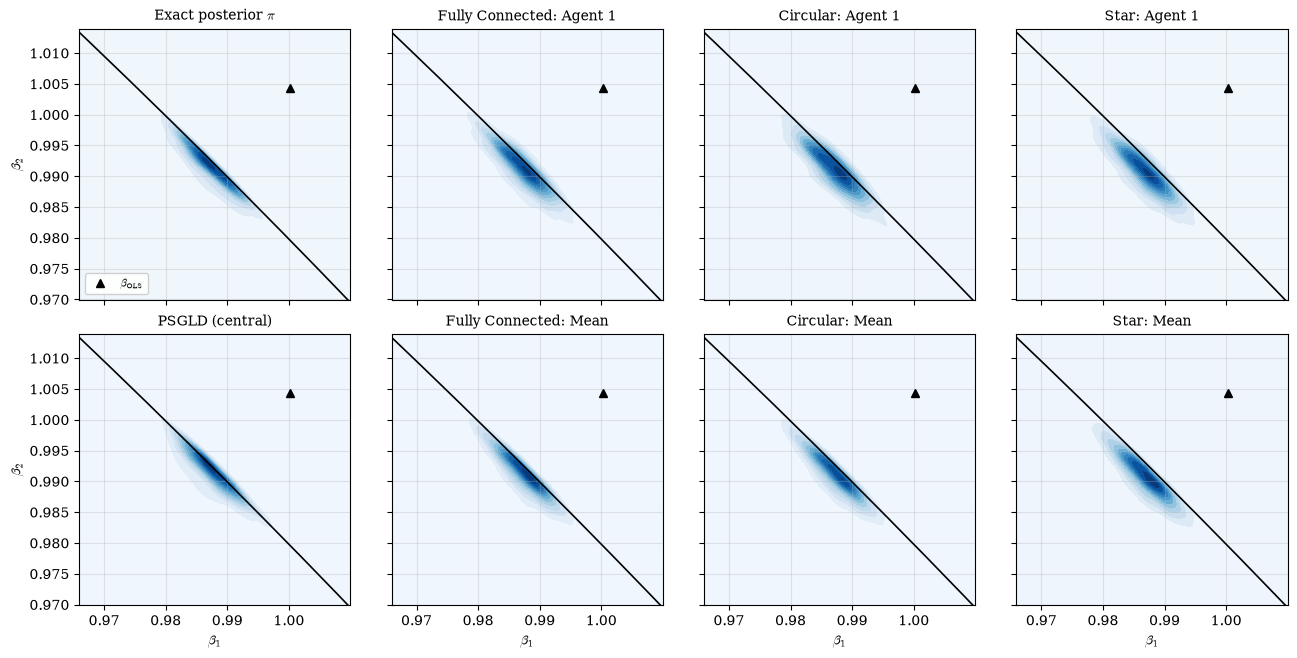

In [6]:
from scipy.stats import gaussian_kde
c = prob.beta_ols * S / np.linalg.norm(prob.beta_ols)          # boundary point closest to beta_OLS
lo, hi = c - ZOOM, c + ZOOM
gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 150), np.linspace(lo[1], hi[1], 150))
th = np.linspace(0, 2 * np.pi, 2000)

def panel(ax, pts, title):
    z = gaussian_kde(pts.T)(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
    ax.contourf(gx, gy, z, levels=12, cmap="Blues")
    ax.plot(S * np.cos(th), S * np.sin(th), "k-", lw=1.2)
    ax.plot(*prob.beta_ols, "k^", ms=6, label=r"$\beta_{\rm OLS}$")
    ax.set_title(title, fontsize=10); ax.set_aspect("equal")
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])

fig, axes = plt.subplots(2, len(NETWORKS) + 1, figsize=(3.3 * (len(NETWORKS) + 1), 6.6), sharex=True, sharey=True)
panel(axes[0, 0], ref, r"Exact posterior $\pi$")
panel(axes[1, 0], BC, "PSGLD (central)")
for j, kind in enumerate(NETWORKS):
    panel(axes[0, j + 1], res[kind]["final"][:, 0], f"{NETWORK_NAMES[kind]}: Agent 1")
    panel(axes[1, j + 1], res[kind]["final"].mean(1), f"{NETWORK_NAMES[kind]}: Mean")
for ax in axes[1]: ax.set_xlabel(r"$\beta_1$")
for ax in axes[:, 0]: ax.set_ylabel(r"$\beta_2$")
axes[0, 0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
if SAVE_FIGS:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"exp2_contours.{ext}", dpi=200, bbox_inches="tight")

## Summary

In [7]:
inside = lambda B: np.mean(np.linalg.norm(B, axis=1) <= S)
rows = [dict(network=NETWORK_NAMES[k], rho=res[k]["rho"], W2_mean=res[k]["mean"][-1],
             **{f"W2_agent{i+1}": v for i, v in zip(AGENTS_TO_SHOW, res[k]["agents"][-1])},
             inside_K_agent1=inside(res[k]["final"][:, 0]), inside_K_mean=inside(res[k]["final"].mean(1)))
        for k in NETWORKS]
rows.append(dict(network="PSGLD (central)", W2_mean=w2_central[-1], inside_K_mean=inside(BC)))
pd.DataFrame(rows).round(4)

,network,rho,W2_mean,W2_agent1,W2_agent5,W2_agent9,inside_K_agent1,inside_K_mean
0,Fully Connected,0.0000,0.0005,0.0006,0.0006,0.0006,0.849,0.898
1,Circular,0.8727,0.0006,0.0007,0.0007,0.0007,0.851,0.938
2,Star,0.9000,0.0009,0.0009,0.0012,0.0012,0.930,0.982
3,PSGLD (central),NaN,0.0006,NaN,NaN,NaN,NaN,0.746
